In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

In [8]:

# Fetch the data.
df = pd.read_csv("https://ourworldindata.org/grapher/children-born-per-woman.csv?v=1&csvType=full&useColumnShortNames=true", storage_options = {'User-Agent': 'Our World In Data data fetch/1.0'})

# Fetch the metadata
metadata = requests.get("https://ourworldindata.org/grapher/children-born-per-woman.metadata.json?v=1&csvType=full&useColumnShortNames=true").json()

In [9]:
df.head(3)

,entity,code,year,fertility_rate_hist
0,Afghanistan,AFG,1950,7.248
1,Afghanistan,AFG,1951,7.260
2,Afghanistan,AFG,1952,7.260


In [10]:
df.shape

(19402, 4)

In [11]:
df.columns.tolist()

['entity', 'code', 'year', 'fertility_rate_hist']

In [12]:
df.dtypes

entity                     str
code                       str
year                     int64
fertility_rate_hist    float64
dtype: object

In [13]:
mexico = df[(df ["entity"] == "Mexico")]

In [14]:
japon = df[df ["entity"] == "Japan"]

In [15]:
type(mexico)

pandas.DataFrame

In [16]:
mexico.head(10)

,entity,code,year,fertility_rate_hist
11125,Mexico,MEX,1950,6.709
11126,Mexico,MEX,1951,6.727
11127,Mexico,MEX,1952,6.731
11128,Mexico,MEX,1953,6.734
11129,Mexico,MEX,1954,6.745
11130,Mexico,MEX,1955,6.730
11131,Mexico,MEX,1956,6.743
11132,Mexico,MEX,1957,6.752
11133,Mexico,MEX,1958,6.758
11134,Mexico,MEX,1959,6.758


In [18]:
anios_mexico = mexico["year"].to_numpy()
tasa_mexico = mexico["fertility_rate_hist"].to_numpy()

anios_japon = japon["year"].to_numpy()
tasa_japon = japon["fertility_rate_hist"].to_numpy()

In [19]:
type(anios_mexico)

numpy.ndarray

In [20]:
promedio_mexico = np.mean(tasa_mexico)
maximo_mexico = np.max(tasa_mexico)

minimo_mexico = np.min(tasa_mexico)

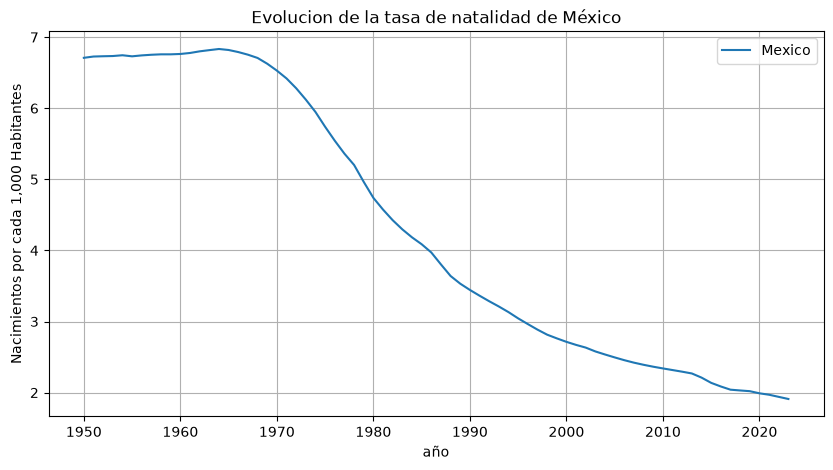

In [25]:
plt.figure(figsize=(10,5))
plt.plot(
    anios_mexico,
    tasa_mexico,
    label="Mexico"
)

plt.title("Evolucion de la tasa de natalidad de México")
plt.xlabel("año")
plt.ylabel("Nacimientos por cada 1,000 Habitantes")
plt.grid(True)
plt.legend()

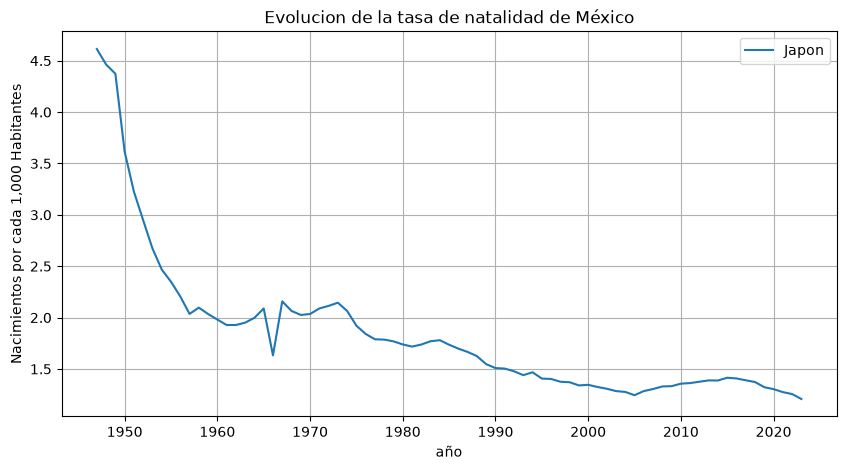

In [ ]:

plt.figure(figsize=(10,5))
plt.plot(
    anios_japon,
    tasa_japon,
    label="Japon"
)

plt.title("Evolucion de la tasa de natalidad de Japón")
plt.xlabel("año")
plt.ylabel("Nacimientos por cada 1,000 Habitantes")
plt.grid(True)
plt.legend()

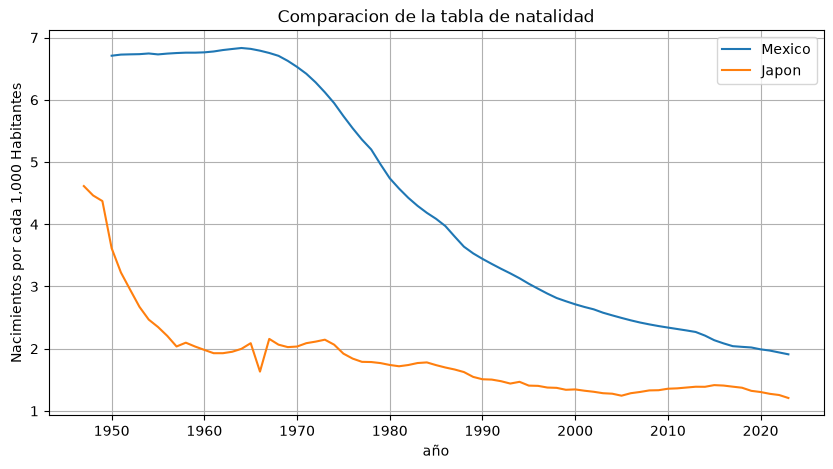

In [26]:
plt.figure(figsize=(10,5))
plt.plot(
    anios_mexico,
    tasa_mexico,
    label="Mexico"
)

plt.plot(
    anios_japon,
    tasa_japon,
    label="Japon"
)

plt.title("Comparacion de la tabla de natalidad")
plt.xlabel("año")
plt.ylabel("Nacimientos por cada 1,000 Habitantes")
plt.grid(True)
plt.legend()

In [27]:
mexico.shape

(74, 4)

In [28]:
japon.shape

(77, 4)

In [30]:
print(anios_mexico[0])

1950


In [31]:
print(anios_japon[0])

1947


In [33]:
diferencia = tasa_mexico - tasa_japon

ValueError: operands could not be broadcast together with shapes (74,) (77,) 

In [34]:
mascara_coincidencia_anios = anios_japon >= anios_mexico.min()

In [36]:
mascara_coincidencia_anios.shape

(77,)

In [37]:
mascara_coincidencia_anios

array([False, False, False,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True])

In [38]:
anios_japon = anios_japon[mascara_coincidencia_anios]

In [39]:
tasa_japon = tasa_japon[mascara_coincidencia_anios]

In [40]:
anios_japon.shape

(74,)

In [43]:
tasa_japon.shape

(74,)

In [44]:
diferencia_mx_jp = tasa_mexico - tasa_japon

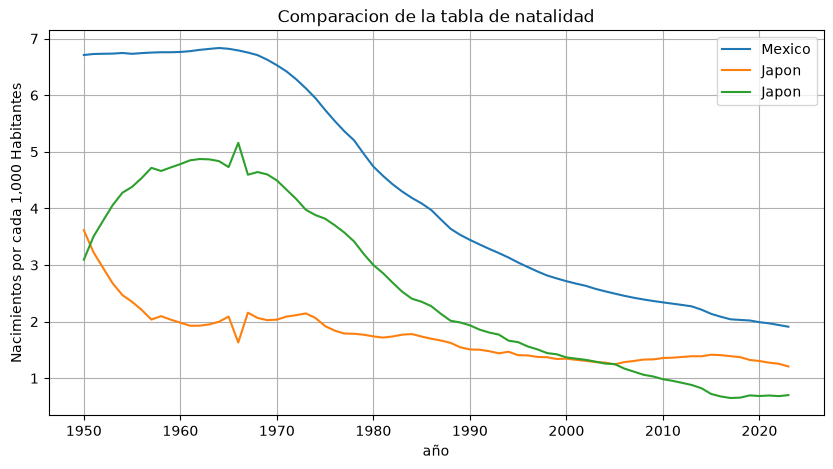

In [45]:
plt.figure(figsize=(10,5))
plt.plot(
    anios_mexico,
    tasa_mexico,
    label="Mexico"
)

plt.plot(
    anios_japon,
    tasa_japon,
    label="Japon"
)

plt.plot(
    anios_japon,
    diferencia_mx_jp,
    label="Japon"
)
plt.title("Comparacion de la tabla de natalidad")
plt.xlabel("año")
plt.ylabel("Nacimientos por cada 1,000 Habitantes")
plt.grid(True)
plt.legend()

In [46]:
anios_comunes = np.intersect1d(
    anios_mexico,
    anios_japon
)